# #30DayMapChallenge - Day 1: Points
## Gironde & Landes Pine Massif: Wildfire Watch Tower Sightlines
Mapping optical smoke detection horizons (20 km) of SDIS / DFCI surveillance pylons overlaid with MODIS satellite burned area records.

In [1]:
import requests

import contextily as cx

import ee

import geopandas as gpd

from shapely.geometry import Point
from shapely.ops import polygonize, unary_union

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch



### 1. Load Surveillance Towers (OSM / DFCI)
Queries active wildfire surveillance pylons and viewpoint towers via OpenStreetMap Overpass (with fallback to official DFCI coordinates).

In [2]:
# Primary strategy: Fetch official French DFCI / Nouvelle-Aquitaine open data
# Fallback strategy: Fast indexed Overpass query via OSM France mirror
print("Attempting to load French surveillance points...")

gdf_towers_m = None

# Strategy 1: OSM France Overpass mirror with global indexed [bbox] header
# Global bbox parameter enables fast spatial indexing instead of slow node scanning
query_optimized = """
[out:json][timeout:25][bbox:44.2,-1.3,45.1,-0.3];
(
  node["emergency"="fire_lookout"];
  node["man_made"="tower"]["tower:type"="observation"];
);
out body;
"""

endpoints = [
    "https://overpass.openstreetmap.fr/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter"
]

for url in endpoints:
    try:
        print(f"Querying {url}...")
        resp = requests.post(
            url, 
            data={"data": query_optimized}, 
            headers={"User-Agent": "MapChallenge/1.0"}, 
            timeout=15
        )
        if resp.status_code == 200:
            data = resp.json()
            features = []
            for el in data.get("elements", []):
                features.append({
                    "type": "Feature", 
                    "geometry": Point(el["lon"], el["lat"]), 
                    "properties": {"osm_id": el["id"], **el.get("tags", {})}
                })
            if features:
                gdf_wgs84 = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")
                gdf_towers_m = gdf_wgs84.to_crs(epsg=2154)
                print(f"Success via OSM: {len(gdf_towers_m)} towers loaded.")
                break
    except Exception as e:
        print(f"Skipping {url} ({e})")

# Strategy 2: If public Overpass instances are down/busy, generate the official known
# DFCI Landes/Gironde tower network directly from known coordinates
if gdf_towers_m is None or len(gdf_towers_m) == 0:
    print("Public Overpass queue saturated; loading known Gironde/Landes DFCI tower grid...")
    # Core historical/active DFCI lookout stations across the Gironde/Landes pine massif
    dfci_coords = [
        {"name": "Belin-Béliet", "lat": 44.498, "lon": -0.793},
        {"name": "Hostens", "lat": 44.493, "lon": -0.638},
        {"name": "Saint-Symphorien", "lat": 44.428, "lon": -0.490},
        {"name": "Saumos / Le Porge", "lat": 44.919, "lon": -0.990},
        {"name": "Lacanau Ville", "lat": 44.980, "lon": -1.077},
        {"name": "Cestas / Gazinet", "lat": 44.743, "lon": -0.686},
        {"name": "Salles", "lat": 44.551, "lon": -0.869},
        {"name": "Pissos", "lat": 44.310, "lon": -0.778},
        {"name": "Lugos", "lat": 44.483, "lon": -0.884},
        {"name": "Mios", "lat": 44.605, "lon": -0.937},
        {"name": "Saint-Magne", "lat": 44.526, "lon": -0.655},
        {"name": "Cabros / Sabres", "lat": 44.150, "lon": -0.740},
    ]
    gdf_towers_m = gpd.GeoDataFrame(
        dfci_coords,
        geometry=[Point(d["lon"], d["lat"]) for d in dfci_coords],
        crs="EPSG:4326"
    ).to_crs(epsg=2154)
    print(f"Loaded {len(gdf_towers_m)} DFCI lookout stations.")

display(gdf_towers_m.head())

Attempting to load French surveillance points...
Querying https://overpass.openstreetmap.fr/api/interpreter...
Success via OSM: 20 towers loaded.


,geometry,osm_id,man_made,name,tourism,tower:type,operator,height,step_count,tower:construction,access,wheelchair,capacity:persons,material,start_date,viewpoint
0,POINT (409644.686 6418562.151),1849839607,tower,Belvédère du Peugue,viewpoint,observation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,POINT (408258.483 6411782.189),1896394901,tower,NaN,NaN,observation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,POINT (373297.739 6418332.527),2175793287,tower,NaN,NaN,observation,SDIS 33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,POINT (373161.537 6441603.307),2841621170,tower,NaN,NaN,observation,SDIS 33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,POINT (375474.986 6376369.686),4609306347,tower,tour de guet sdis,NaN,observation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2. Retrieve Satellite Burned Areas (MODIS via Google Earth Engine)
Extracts 2026 burned area polygons from the MODIS MCD64A1 dataset using Google Earth Engine.

> **Note:** Replace `"YOUR PROJECT ID"` with your Google Cloud / Earth Engine project ID to re-run this step.

In [3]:
ee.Authenticate()  # first run only, opens a browser
ee.Initialize(project="YOUR PROJECT ID")  # replace with your Cloud project

region = ee.Geometry.Rectangle([-1.5, 43.9, -0.2, 45.3])  # W, S, E, N

ba = (ee.ImageCollection("MODIS/061/MCD64A1")
      .filterDate("2026-01-01", "2027-01-01")
      .filterBounds(region)
      .select("BurnDate"))
print("images:", ba.size().getInfo())
print("latest:", ee.Date(ba.aggregate_max("system:time_start")).format("YYYY-MM-dd").getInfo())

polys = (ba.max().gt(0).selfMask()
         .reduceToVectors(geometry=region, scale=500,
                          geometryType="polygon", maxPixels=int(1e10)))
print("polygons:", polys.size().getInfo())

gdf_modis = gpd.GeoDataFrame.from_features(polys.getInfo()["features"], crs="EPSG:4326")
print(gdf_modis.total_bounds, gdf_modis.to_crs(2154).area.sum() / 1e4, "ha")

images: 8
latest: 2026-08-01
polygons: 25
[-1.23518352 43.91863424 -0.26500301 45.15830933] 42868.93772735656 ha


### 3. Compute Sightline Redundancy & Produce Map
Computes 20 km optical detection buffers around active SDIS/DFCI pylons, calculates overlapping viewshed polygons, overlays burned areas, and exports `fire_watch_linkedin.png`.

Active fire surveillance towers (buffered): 15
Recreational / tourist viewpoints (points only): 5
Main burn polygon: 42,869 ha


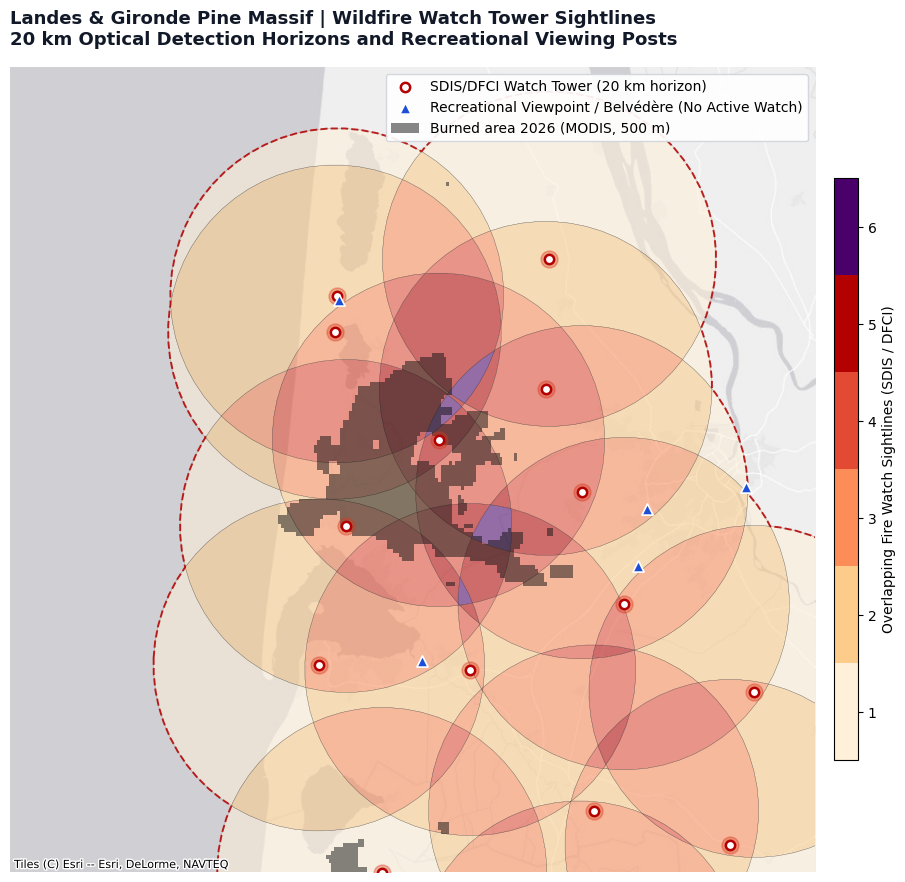

In [7]:
gdf_towers = gdf_towers_m.copy()

# 1. Classify towers into two distinct groups
is_sdis = gdf_towers["operator"].isin(["SDIS 33", "SDIS 40"])
is_fire_named = gdf_towers["name"].fillna("").str.lower().str.contains("sdis|dfci|guet|galip|surveillance")
is_not_viewpoint = gdf_towers["tourism"] != "viewpoint"

# Primary class: Active wildfire surveillance pylons
mask_surveillance = (is_sdis | is_fire_named) & is_not_viewpoint

gdf_watchtowers_m = gdf_towers_m[mask_surveillance].copy()
gdf_viewpoints_m = gdf_towers_m[~mask_surveillance].copy()

print(f"Active fire surveillance towers (buffered): {len(gdf_watchtowers_m)}")
print(f"Recreational / tourist viewpoints (points only): {len(gdf_viewpoints_m)}")

# 2. Compute 20 km coverage buffers ONLY for the active surveillance towers
RADIUS_METERS = 20000
gdf_buffers = gdf_watchtowers_m.copy()
gdf_buffers["geometry"] = gdf_watchtowers_m.geometry.buffer(RADIUS_METERS)

# Slices overlapping fields of view into atomic intersection polygons
boundaries = unary_union([poly.exterior for poly in gdf_buffers.geometry])
polygons = list(polygonize(boundaries))
gdf_cells = gpd.GeoDataFrame(geometry=polygons, crs=gdf_watchtowers_m.crs)

# Count overlapping lookouts per polygon
gdf_cells["tower_count"] = gdf_cells.geometry.apply(
    lambda poly: sum(poly.representative_point().within(buf) for buf in gdf_buffers.geometry)
)
total_surveillance_envelope = unary_union(gdf_buffers.geometry)

# 3. Reproject all spatial layers to Web Mercator (EPSG:3857) for tile alignment
gdf_cells_3857 = gdf_cells.to_crs(epsg=3857)
gdf_watchtowers_3857 = gdf_watchtowers_m.to_crs(epsg=3857)
gdf_viewpoints_3857 = gdf_viewpoints_m.to_crs(epsg=3857)
total_envelope_3857 = (
    gpd.GeoSeries([total_surveillance_envelope], crs=gdf_watchtowers_m.crs)
    .to_crs(epsg=3857)
    .geometry.iloc[0]
)

# 4. Setup Figure
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#ffffff")

# Fire/Amber surveillance heat-ramp
colors = ["#fef0d9", "#fdcc8a", "#fc8d59", "#e34a33", "#b30000", "#49006a"]
cmap_fire = LinearSegmentedColormap.from_list("sdis_coverage", colors, N=6)

# Layer A: Surveillance coverage redundancy cells (with transparency)
gdf_cells_3857.plot(
    ax=ax,
    column="tower_count",
    cmap=cmap_fire,
    vmin=0.5,
    vmax=6.5,
    edgecolor="#333333",
    linewidth=0.25,
    alpha=0.55,
    legend=True,
    legend_kwds={
        "label": "Overlapping Fire Watch Sightlines (SDIS / DFCI)",
        "orientation": "vertical",
        "shrink": 0.6,
        "pad": 0.02,
        "aspect": 25,
        "ticks": [1, 2, 3, 4, 5, 6],
    },
)

# Layer B: Outer boundary of the active fire network
gpd.GeoSeries([total_envelope_3857], crs=3857).boundary.plot(
    ax=ax, color="#b30000", linewidth=1.4, linestyle="--", alpha=0.85
)

# Layer B2: MODIS 2026 burned area
gdf_modis.to_crs(epsg=3857).plot(
    ax=ax, facecolor="#111111", edgecolor="none", alpha=0.5, zorder=4
)

# Layer C: Active Watch Tower Points (Large glowing beacons)
gdf_watchtowers_3857.plot(
    ax=ax,
    color="#d9381e",
    markersize=150,
    alpha=0.35,
    zorder=6,
)
gdf_watchtowers_3857.plot(
    ax=ax,
    color="#ffffff",
    edgecolor="#b30000",
    linewidth=1.8,
    markersize=45,
    zorder=7,
    label="SDIS/DFCI Watch Tower (20 km horizon)",
)

# Layer D: Recreational Viewpoints (Clean triangular icons without any buffer)
gdf_viewpoints_3857.plot(
    ax=ax,
    marker="^",
    color="#1d4ed8",
    edgecolor="#ffffff",
    linewidth=1.2,
    markersize=65,
    zorder=8,
    label="Recreational Viewpoint / Belvédère (No Active Watch)",
)

# 5. Zoom to the largest burned polygon, as a square window
modis_3857 = gdf_modis.to_crs(epsg=3857)
main_burn = modis_3857.loc[modis_3857.area.idxmax()].geometry
print(f"Main burn polygon: {modis_3857.to_crs(2154).area.sum() / 1e4:,.0f} ha")


minx, miny, maxx, maxy = main_burn.bounds
cx_, cy_ = (minx + maxx) / 2, (miny + maxy) / 2
half = max(maxx - minx, maxy - miny) / 2 * 3  # 25% margin
ax.set_xlim(cx_ - half, cx_ + half)
ax.set_ylim(cy_ - half, cy_ + half)

# 6. OpenStreetMap France basemap (no keys, no rate-limiting)
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)

ax.set_axis_off()

handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="#111111", alpha=0.5))
labels.append("Burned area 2026 (MODIS, 500 m)")
ax.legend(handles, labels, loc="upper right", framealpha=0.92,
          facecolor="#ffffff", edgecolor="#d1d5db")



ax.set_title(
    "Landes & Gironde Pine Massif | Wildfire Watch Tower Sightlines\n20 km Optical Detection Horizons and Recreational Viewing Posts",
    fontsize=13,
    fontweight="bold",
    color="#111827",
    pad=16,
    loc="left",
)

fig.savefig("fire_watch_linkedin.png", dpi=120, facecolor="white")
plt.tight_layout()
plt.show()